# 실습 1. MLP vs CNN — 이미지의 공간 구조 학습

**목표**
- 이미 다뤄본 MLP 코드를 출발점으로, 레이어만 교체해 CNN을 구성
- 동일 데이터(Fashion-MNIST)에서 정확도와 파라미터 수를 비교
- 학습된 필터와 특징 맵(feature map)을 시각화해 CNN이 무엇을 학습하는지 확인

**권장 런타임**: 런타임 → 런타임 유형 변경 → GPU (CPU에서도 수 분 내 실행 가능)

## 0. 환경 설정

In [1]:
# ===== 필요한 라이브러리 불러오기 =====
import torch                                   # PyTorch 기본 패키지 (텐서 연산, 자동 미분)
import torch.nn as nn                          # 신경망 레이어(Linear, Conv2d 등) 모음
import torch.nn.functional as F                # 활성화 함수, 손실 함수 등 함수형 API
from torch.utils.data import DataLoader        # 데이터를 미니배치 단위로 묶어 주는 도구
from torchvision import datasets, transforms   # 이미지 데이터셋과 전처리 도구
import matplotlib.pyplot as plt                # 그래프·이미지 시각화
import time                                    # 학습 시간 측정용

# 난수 시드 고정: 매번 실행해도 같은 결과가 나오도록 (재현성 확보)
torch.manual_seed(42)

# GPU를 쓸 수 있으면 "cuda", 아니면 "cpu"를 사용
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


## 1. 데이터 불러오기
- Fashion-MNIST: 28×28 흑백 의류 이미지, 10개 클래스
- 학습 60,000장 / 테스트 10,000장

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.3MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 211kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.94MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 3.81MB/s]


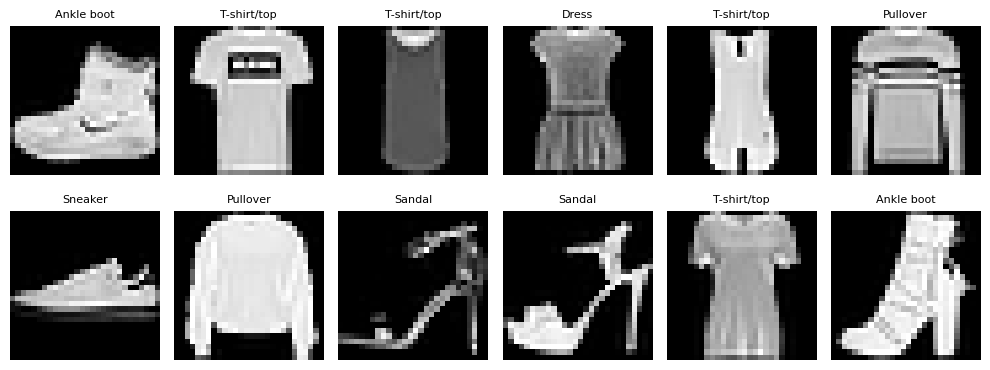

In [2]:
# ===== 전처리 정의 =====
transform = transforms.Compose([
    transforms.ToTensor(),                      # PIL 이미지 → 텐서 (0~255 값을 0~1로 변환, 모양: 1×28×28)
    transforms.Normalize((0.2860,), (0.3530,))  # (값 - 평균) / 표준편차 → 학습이 더 안정적
])                                              # 0.2860, 0.3530은 Fashion-MNIST 전체 픽셀의 평균·표준편차

# ===== 데이터셋 다운로드 및 불러오기 =====
# train=True → 학습용 60,000장, train=False → 테스트용 10,000장
train_ds = datasets.FashionMNIST("./data", train=True, download=True, transform=transform)
test_ds  = datasets.FashionMNIST("./data", train=False, download=True, transform=transform)

# ===== DataLoader: 데이터를 미니배치로 나눠서 공급 =====
# 학습용은 매 epoch마다 순서를 섞어서(shuffle) 모델이 순서를 외우지 않게 함
train_loader = DataLoader(train_ds, batch_size=128, shuffle=True)
# 테스트용은 섞을 필요가 없고, 평가만 하므로 배치를 크게 잡아 빠르게 처리
test_loader  = DataLoader(test_ds, batch_size=512)

# ===== 샘플 이미지 12장 미리보기 =====
classes = train_ds.classes                         # 클래스 이름 목록 (예: 'T-shirt/top', 'Trouser', ...)
fig, axes = plt.subplots(2, 6, figsize=(10, 4))    # 2행 6열 격자
for ax, i in zip(axes.flat, range(12)):
    img, label = train_ds[i]                       # i번째 (이미지, 정답 레이블)
    ax.imshow(img.squeeze(), cmap="gray")          # squeeze(): 1×28×28 → 28×28 (채널 차원 제거)
    ax.set_title(classes[label], fontsize=8)       # 제목에 정답 클래스 이름 표시
    ax.axis("off")                                 # 축 눈금 숨기기
plt.tight_layout(); plt.show()

## 2. 학습·평가 함수 (두 모델 공통)

In [3]:
# ===== 학습 가능한 파라미터 개수 세기 =====
# numel(): 텐서 안의 원소 개수. requires_grad=True인 것(학습되는 가중치)만 합산
def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

# ===== 모델 학습 함수 =====
def train_model(model, epochs=3, lr=1e-3):
    model = model.to(device)                                # 모델을 GPU/CPU로 이동
    opt = torch.optim.Adam(model.parameters(), lr=lr)       # Adam 옵티마이저 (학습률 0.001)
    history = []                                            # epoch별 테스트 정확도 기록
    for ep in range(epochs):
        model.train()                                       # 학습 모드로 전환
        t0 = time.time()
        for x, y in train_loader:                           # 미니배치 하나씩 꺼내기
            x, y = x.to(device), y.to(device)               # 데이터도 모델과 같은 장치로
            loss = F.cross_entropy(model(x), y)             # 예측(model(x))과 정답(y)의 오차 계산
            # 1) 이전 기울기 초기화 → 2) 역전파로 기울기 계산 → 3) 가중치 업데이트
            opt.zero_grad(); loss.backward(); opt.step()
        acc = evaluate(model)                               # epoch이 끝날 때마다 테스트 정확도 측정
        history.append(acc)
        print(f"  epoch {ep+1}: test acc = {acc:.4f}  ({time.time()-t0:.1f}s)")
    return history

# ===== 모델 평가 함수 =====
@torch.no_grad()        # 평가할 때는 기울기 계산이 필요 없으므로 꺼서 메모리·속도 절약
def evaluate(model):
    model.eval()                                            # 평가 모드로 전환
    correct = 0
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        # argmax(1): 10개 클래스 점수 중 가장 큰 것의 인덱스 = 예측 클래스
        correct += (model(x).argmax(1) == y).sum().item()   # 맞힌 개수 누적
    return correct / len(test_ds)                           # 정확도 = 맞힌 개수 / 전체 개수

## 3. 기준 모델: MLP
- 이미지를 784차원 벡터로 **펼쳐서(flatten)** 입력 → 픽셀 간 위치 관계 정보 손실

In [4]:
# ===== MLP (다층 퍼셉트론) 모델 정의 =====
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(                   # 레이어를 순서대로 쌓기
            nn.Flatten(),                           # 1×28×28 이미지를 784개 숫자의 1차원 벡터로 펼침
                                                    #   → 이 과정에서 "어떤 픽셀이 옆에 있었는지" 정보가 사라짐!
            nn.Linear(28*28, 256), nn.ReLU(),       # 784 → 256 (완전 연결층 + 활성화 함수)
            nn.Linear(256, 128),   nn.ReLU(),       # 256 → 128
            nn.Linear(128, 10)                      # 128 → 10 (10개 클래스별 점수 출력)
        )
    def forward(self, x):                           # 입력 x가 모델을 통과하는 방식
        return self.net(x)

mlp = MLP()                                         # 모델 객체 생성
print("MLP 파라미터 수:", f"{count_params(mlp):,}")  # 파라미터 수 출력 (천 단위 콤마)
mlp_hist = train_model(mlp)                         # 학습 시작 (기본 3 epoch)

MLP 파라미터 수: 235,146
  epoch 1: test acc = 0.8468  (15.5s)
  epoch 2: test acc = 0.8519  (14.4s)
  epoch 3: test acc = 0.8743  (14.3s)


## 4. CNN
- `nn.Linear` 대신 `nn.Conv2d` + `nn.MaxPool2d` 사용
- 핵심 개념: 지역 연결(local connectivity), 가중치 공유(weight sharing), 풀링(pooling)
- 텐서 크기 변화: `1×28×28 → 32×28×28 → 32×14×14 → 64×14×14 → 64×7×7 → 10`

In [5]:
# ===== CNN (합성곱 신경망) 모델 정의 =====
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        # Conv2d(입력 채널, 출력 채널, 필터 크기, 패딩)
        # 3×3 필터가 이미지를 훑으며 지역 패턴(선, 모서리 등)을 찾음. padding=1이면 크기 유지
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)   # 1×28×28 → 32×28×28 (흑백 1채널 → 필터 32개)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)  # 32×14×14 → 64×14×14 (필터 64개)
        self.pool  = nn.MaxPool2d(2)                              # 2×2 영역에서 최댓값만 남김 → 공간 크기 1/2
        self.fc    = nn.Linear(64*7*7, 10)                        # 마지막 분류기: 3136 → 10개 클래스

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))   # 합성곱 → ReLU → 풀링 : → 32×14×14
        x = self.pool(F.relu(self.conv2(x)))   # 합성곱 → ReLU → 풀링 : → 64×7×7
        x = torch.flatten(x, 1)                # 배치 차원(0번)은 두고 나머지를 펼침 → 3136차원 벡터
        return self.fc(x)                      # 10개 클래스 점수 출력

cnn = CNN()
print("CNN 파라미터 수:", f"{count_params(cnn):,}")  # MLP보다 훨씬 적은 것을 확인해 보세요 (가중치 공유 덕분)
cnn_hist = train_model(cnn)                         # MLP와 똑같은 조건으로 학습

CNN 파라미터 수: 50,186
  epoch 1: test acc = 0.8831  (19.3s)
  epoch 2: test acc = 0.8936  (15.1s)
  epoch 3: test acc = 0.9005  (14.6s)


## 5. 결과 비교

모델            파라미터      최종 정확도
MLP        235,146      0.8743
CNN         50,186      0.9005


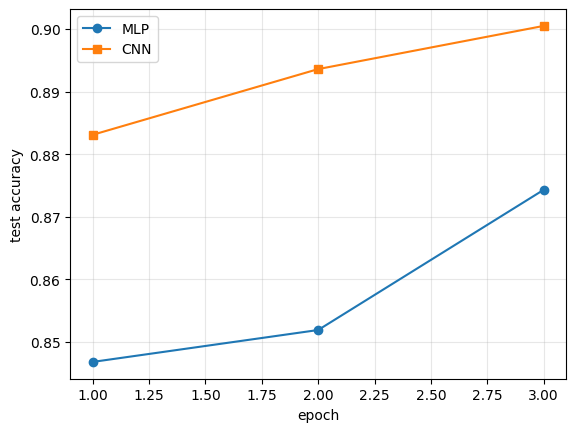

In [6]:
# ===== 표로 비교 출력 =====
# :<6 → 왼쪽 정렬 6칸, :>12 → 오른쪽 정렬 12칸, :, → 천 단위 콤마, .4f → 소수점 4자리
print(f"{'모델':<6}{'파라미터':>12}{'최종 정확도':>12}")
print(f"{'MLP':<6}{count_params(mlp):>12,}{mlp_hist[-1]:>12.4f}")   # [-1]: 마지막 epoch 정확도
print(f"{'CNN':<6}{count_params(cnn):>12,}{cnn_hist[-1]:>12.4f}")

# ===== epoch별 정확도 그래프 =====
plt.plot(range(1, len(mlp_hist)+1), mlp_hist, "o-", label="MLP")    # 동그라미 마커 + 실선
plt.plot(range(1, len(cnn_hist)+1), cnn_hist, "s-", label="CNN")    # 네모 마커 + 실선
plt.xlabel("epoch"); plt.ylabel("test accuracy"); plt.legend(); plt.grid(alpha=.3)  # 축 이름, 범례, 옅은 격자
plt.show()

## 6. CNN이 학습한 것 들여다보기
- 첫 번째 합성곱 층의 필터(3×3) 32개
- 한 이미지에 대한 특징 맵(feature map)

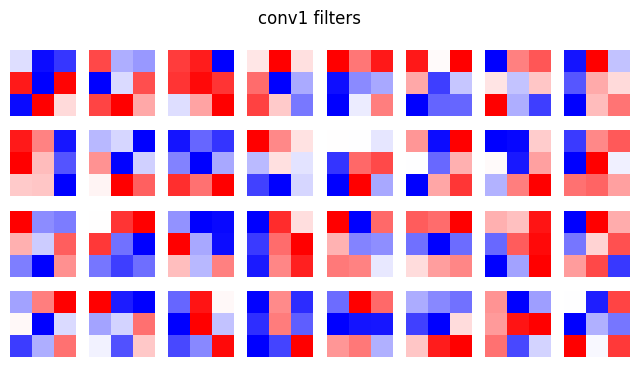

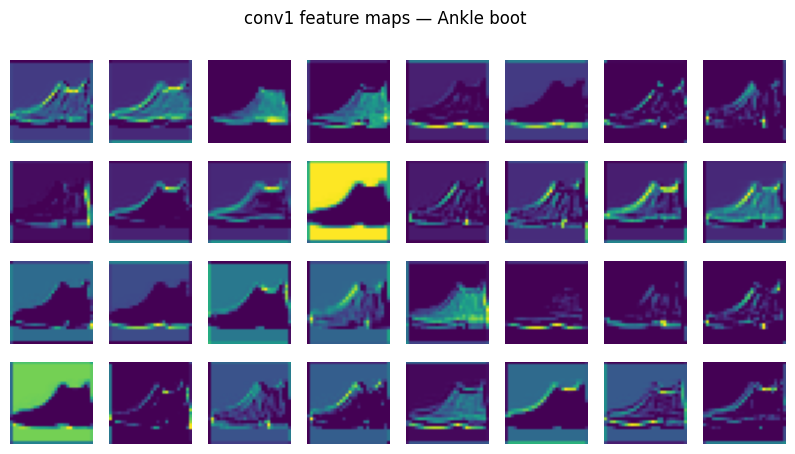

In [7]:
# (1) 첫 층 필터 시각화
# detach(): 기울기 추적에서 분리, cpu(): matplotlib은 CPU 텐서만 그릴 수 있음
w = cnn.conv1.weight.detach().cpu()   # (32, 1, 3, 3) = 필터 32개, 각각 1채널 3×3
fig, axes = plt.subplots(4, 8, figsize=(8, 4))      # 4×8 = 32칸
for ax, k in zip(axes.flat, w):
    # bwr 컬러맵: 빨강=양수 가중치, 파랑=음수 가중치 → 어떤 방향의 경계를 감지하는지 보임
    ax.imshow(k.squeeze(), cmap="bwr"); ax.axis("off")
plt.suptitle("conv1 filters"); plt.show()

# (2) 특징 맵 시각화: 테스트 이미지 1장이 conv1을 통과한 결과
img, label = test_ds[0]                              # 테스트셋 첫 번째 이미지
with torch.no_grad():                                # 시각화만 하므로 기울기 계산 끔
    # unsqueeze(0): 1×28×28 → 1×1×28×28 (모델은 배치 차원이 필요)
    # [0]: 배치 차원 다시 제거
    fmap = F.relu(cnn.conv1(img.unsqueeze(0).to(device))).cpu()[0]  # (32, 28, 28)
fig, axes = plt.subplots(4, 8, figsize=(10, 5))
for ax, m in zip(axes.flat, fmap):
    # 밝은 부분 = 해당 필터가 강하게 반응한 위치
    ax.imshow(m, cmap="viridis"); ax.axis("off")
plt.suptitle(f"conv1 feature maps — {classes[label]}"); plt.show()

## 7. 추가 과제
1. MLP의 은닉층 크기를 늘려 CNN과 파라미터 수를 비슷하게 맞추면 정확도 차이는 어떻게 되는가?
2. `MaxPool2d`를 제거하면 파라미터 수와 정확도는 어떻게 변하는가? (힌트: `fc` 입력 크기 수정 필요)
3. 합성곱 층을 하나 더 추가하고, 텐서 크기 변화를 직접 계산해 보라.
4. (토론) 위성영상·가로 경관 이미지 분석에서 CNN의 어떤 성질이 유리한가?

### 추가 과제 1. MLP와 CNN의 파라미터 수 맞추기
- 현재 CNN(약 5만 개)이 MLP(약 23.5만 개)보다 파라미터가 **훨씬 적음**
- (a) MLP를 CNN과 비슷한 크기(약 5만 개)로 맞춘 경우, (b) MLP를 오히려 크게 키운 경우를 모두 비교

In [9]:
# ===== 은닉층 크기를 바꿀 수 있는 MLP =====
class MLPCustom(nn.Module):
    def __init__(self, h1, h2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),                      # 1×28×28 → 784
            nn.Linear(28*28, h1), nn.ReLU(),   # 784 → h1
            nn.Linear(h1, h2),    nn.ReLU(),   # h1 → h2
            nn.Linear(h2, 10)                  # h2 → 10
        )
    def forward(self, x):
        return self.net(x)

# (a) CNN과 파라미터 수를 비슷하게 맞춘 MLP
#     784*60+60 + 60*32+32 + 32*10+10 = 49,382개 (CNN: 50,186개)
mlp_small = MLPCustom(60, 32)
print("MLP(60, 32) 파라미터 수:", f"{count_params(mlp_small):,}")
mlp_small_hist = train_model(mlp_small)

# (b) 은닉층을 크게 늘린 MLP (파라미터 수가 CNN의 약 27배)
mlp_big = MLPCustom(1024, 512)
print("MLP(1024, 512) 파라미터 수:", f"{count_params(mlp_big):,}")
mlp_big_hist = train_model(mlp_big)

# ===== 결과 비교 =====
print(f"\n{'모델':<16}{'파라미터':>12}{'최종 정확도':>12}")
for name, model, hist in [("MLP(256,128)", mlp, mlp_hist),
                          ("MLP(60,32)", mlp_small, mlp_small_hist),
                          ("MLP(1024,512)", mlp_big, mlp_big_hist),
                          ("CNN", cnn, cnn_hist)]:
    print(f"{name:<16}{count_params(model):>12,}{hist[-1]:>12.4f}")
# 관찰 포인트: 파라미터를 27배 늘려도 MLP가 CNN을 따라잡기 어렵다면,
#             CNN의 강점은 "크기"가 아니라 "구조(공간 정보 활용)"에서 나온다는 뜻

MLP(60, 32) 파라미터 수: 49,382
  epoch 1: test acc = 0.8418  (13.8s)
  epoch 2: test acc = 0.8534  (13.7s)
  epoch 3: test acc = 0.8602  (14.4s)
MLP(1024, 512) 파라미터 수: 1,333,770
  epoch 1: test acc = 0.8364  (14.0s)
  epoch 2: test acc = 0.8649  (14.2s)
  epoch 3: test acc = 0.8797  (14.0s)

모델                      파라미터      최종 정확도
MLP(256,128)         235,146      0.8743
MLP(60,32)            49,382      0.8602
MLP(1024,512)      1,333,770      0.8797
CNN                   50,186      0.9005


### 추가 과제 2. MaxPool2d 제거하기
- 풀링이 없으면 공간 크기가 줄지 않아 마지막 특징 맵이 **64×28×28** 그대로 남음
- 따라서 `fc`의 입력 크기를 `64*7*7` → `64*28*28`로 바꿔야 함

In [10]:
# ===== 풀링이 없는 CNN =====
class CNNNoPool(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)   # 1×28×28 → 32×28×28
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)  # 32×28×28 → 64×28×28
        self.fc    = nn.Linear(64*28*28, 10)                      # 50,176 → 10  (여기가 핵심 수정!)

    def forward(self, x):
        x = F.relu(self.conv1(x))      # → 32×28×28 (풀링 없음, 크기 유지)
        x = F.relu(self.conv2(x))      # → 64×28×28
        x = torch.flatten(x, 1)        # → 50,176차원
        return self.fc(x)

cnn_nopool = CNNNoPool()
# fc층만 50,176*10+10 = 501,770개 → 전체 파라미터가 약 10배로 늘어남
print("CNN(풀링 없음) 파라미터 수:", f"{count_params(cnn_nopool):,}")
cnn_nopool_hist = train_model(cnn_nopool)

print(f"\n{'모델':<14}{'파라미터':>12}{'최종 정확도':>12}")
print(f"{'CNN(풀링)':<14}{count_params(cnn):>12,}{cnn_hist[-1]:>12.4f}")
print(f"{'CNN(풀링X)':<14}{count_params(cnn_nopool):>12,}{cnn_nopool_hist[-1]:>12.4f}")
# 관찰 포인트: 풀링은 파라미터·연산량을 크게 줄이고, 위치가 조금 바뀌어도
#             같은 특징으로 인식하게 해 줌(이동 불변성). 정확도와 학습 시간도 함께 비교해 보세요.

CNN(풀링 없음) 파라미터 수: 520,586
  epoch 1: test acc = 0.8904  (14.1s)
  epoch 2: test acc = 0.9041  (13.9s)
  epoch 3: test acc = 0.9096  (14.1s)

모델                    파라미터      최종 정확도
CNN(풀링)             50,186      0.9005
CNN(풀링X)           520,586      0.9096


### 추가 과제 3. 합성곱 층 하나 더 추가하기
- 텐서 크기 변화 직접 계산:
  - 입력 `1×28×28`
  - conv1(3×3, pad 1) → `32×28×28` → pool → `32×14×14`
  - conv2(3×3, pad 1) → `64×14×14` → pool → `64×7×7`
  - conv3(3×3, pad 1) → `128×7×7` → pool → `128×3×3` (7÷2 = 3.5 → **내림해서 3**)
  - flatten → `1152` → fc → `10`
- 합성곱 출력 크기 공식: (입력 - 커널 + 2×패딩) / 스트라이드 + 1 = (28 - 3 + 2) / 1 + 1 = 28

In [11]:
# ===== 합성곱 층이 3개인 CNN =====
class CNN3(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)    # 1×28×28  → 32×28×28
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)   # 32×14×14 → 64×14×14
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)  # 64×7×7   → 128×7×7  (새로 추가)
        self.pool  = nn.MaxPool2d(2)                               # 공간 크기 1/2 (홀수면 내림)
        self.fc    = nn.Linear(128*3*3, 10)                        # 1,152 → 10

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))   # → 32×14×14
        x = self.pool(F.relu(self.conv2(x)))   # → 64×7×7
        x = self.pool(F.relu(self.conv3(x)))   # → 128×3×3
        x = torch.flatten(x, 1)                # → 1,152
        return self.fc(x)

cnn3 = CNN3()

# ===== 손으로 계산한 크기가 맞는지 가짜 입력으로 확인 =====
with torch.no_grad():
    t = torch.zeros(1, 1, 28, 28)              # 배치 1장짜리 빈 이미지
    print("입력        :", tuple(t.shape[1:]))
    t = cnn3.pool(F.relu(cnn3.conv1(t))); print("conv1+pool  :", tuple(t.shape[1:]))
    t = cnn3.pool(F.relu(cnn3.conv2(t))); print("conv2+pool  :", tuple(t.shape[1:]))
    t = cnn3.pool(F.relu(cnn3.conv3(t))); print("conv3+pool  :", tuple(t.shape[1:]))
    t = torch.flatten(t, 1);              print("flatten     :", tuple(t.shape[1:]))

print("\nCNN3 파라미터 수:", f"{count_params(cnn3):,}")
cnn3_hist = train_model(cnn3)

print(f"\n{'모델':<10}{'파라미터':>12}{'최종 정확도':>12}")
print(f"{'CNN(2층)':<10}{count_params(cnn):>12,}{cnn_hist[-1]:>12.4f}")
print(f"{'CNN(3층)':<10}{count_params(cnn3):>12,}{cnn3_hist[-1]:>12.4f}")

# ============================================================
# [실행 결과 해설]
# ============================================================
# (1) 텐서 크기 확인
#   - 출력이 1×28×28 → 32×14×14 → 64×7×7 → 128×3×3 → 1152 로 나와
#     설명 셀에서 손으로 계산한 값과 정확히 일치함
#   - 7×7에 2×2 풀링을 하면 3.5가 아니라 3으로 "내림"됨
#     → 7번째 행·열 픽셀 정보는 버려진다는 점도 기억해 두기
#
# (2) 파라미터 수: 50,186 → 104,202 (약 2배)
#   - conv1 : 1*32*3*3 + 32      =    320
#   - conv2 : 32*64*3*3 + 64     = 18,496
#   - conv3 : 64*128*3*3 + 128   = 73,856  ← 늘어난 대부분이 여기
#   - fc    : 1152*10 + 10       = 11,530  (2층 CNN의 fc 31,370개보다 오히려 줄어듦)
#   - 합계                        = 104,202
#   → 층이 깊어질수록 채널 수가 커져 합성곱 층 파라미터가 늘고,
#     대신 공간 크기가 작아져 마지막 fc 층은 가벼워짐
#
# (3) 정확도: 3층(0.8888) < 2층(0.9005), 층을 늘렸는데 오히려 약 1.2%p 낮아짐
#   - 학습 부족: 정확도가 0.8691 → 0.8846 → 0.8888로 아직 오르는 중
#     파라미터가 2배인 더 깊은 모델은 3 epoch로는 충분히 수렴하지 못함
#   - 과도한 압축: 28×28 작은 이미지를 3×3까지 줄이면 공간 정보가 너무 많이 사라짐
#     (Fashion-MNIST처럼 작고 단순한 이미지에는 2층이면 충분)
#   - 우연성: 시드·초기화에 따라 ±0.5%p 정도 오차가 날 수 있어 한 번의 결과로 단정은 금물
#
# (4) 결론과 더 해 볼 것
#   - "층을 깊게 = 무조건 성능 향상"이 아님. 데이터 크기·해상도에 맞는 깊이가 중요
#   - train_model(cnn3, epochs=10)처럼 epoch를 늘려 다시 비교해 보기
#   - 세 번째 풀링을 빼서 128×7×7을 유지하거나, nn.BatchNorm2d를 넣어 학습 안정화해 보기
#   - 위성·가로 경관처럼 고해상도 이미지에서는 깊은 CNN의 이점이 훨씬 크게 나타남

입력        : (1, 28, 28)
conv1+pool  : (32, 14, 14)
conv2+pool  : (64, 7, 7)
conv3+pool  : (128, 3, 3)
flatten     : (1152,)

CNN3 파라미터 수: 104,202
  epoch 1: test acc = 0.8691  (13.9s)
  epoch 2: test acc = 0.8846  (15.2s)
  epoch 3: test acc = 0.8888  (14.1s)

모델                파라미터      최종 정확도
CNN(2층)         50,186      0.9005
CNN(3층)        104,202      0.8888


### 추가 과제 4. (토론) 위성영상·가로 경관 이미지 분석에서 CNN의 어떤 성질이 유리한가?

**1. 지역 연결 (local connectivity)**
- 위성영상의 도로, 건물 지붕, 농경지 경계나 가로 경관의 창문, 간판, 나무, 차량은 모두 **가까운 픽셀끼리 모여서** 의미가 생기는 패턴이에요.
- CNN은 작은 필터로 주변 픽셀만 보기 때문에 이런 지역 패턴을 자연스럽게 잡아내요. MLP처럼 이미지를 펼치면 이 공간 관계가 사라져요 (과제 1에서 MLP는 파라미터를 27배 늘려도 CNN을 못 이겼어요).

**2. 가중치 공유 → 이동 등변성 (translation equivariance)**
- 같은 필터를 이미지 전체에 적용하므로 **건물이나 나무가 사진 어디에 있든** 같은 방식으로 감지해요.
- 위성영상에서는 같은 대상(주택, 수역, 녹지)이 화면 곳곳에 반복해서 나타나고, 가로 경관에서도 보행자·차량의 위치가 사진마다 달라서 이 성질이 특히 중요해요.

**3. 파라미터 효율성**
- 위성영상은 한 장이 수천×수천 픽셀이고 가로 경관 이미지도 고해상도예요. MLP로 처리하면 첫 층 파라미터만 수억 개가 넘어 현실적으로 불가능해요.
- CNN은 필터 크기만큼만 파라미터가 필요해서 이미지 크기와 상관없이 모델이 가벼워요 (실습에서 CNN 5만 개 vs MLP 23.5만 개).

**4. 풀링과 계층적 특징 학습**
- 앞쪽 층은 선·모서리·질감을, 뒤쪽 층은 이들을 조합해 "건물", "도로망", "가로수 길" 같은 고수준 개념을 학습해요 (6번 시각화에서 본 필터가 그 첫 단계예요).
- 풀링은 위치가 조금 어긋나도 같은 특징으로 인식하게 해 주어 촬영 각도·정렬 오차에 강해져요.

**5. 다채널 입력**
- `Conv2d`의 입력 채널 수만 바꾸면 RGB 외에 근적외선(NIR), 다중분광 밴드, DEM(고도) 같은 위성 데이터도 그대로 넣을 수 있어요 (흑백 1채널 → 다채널).

**6. 전이 학습(transfer learning)**
- ImageNet 등으로 미리 학습된 CNN의 하위 층 특징(선, 질감)은 범용적이어서, 라벨이 적은 도시·환경 데이터에도 적은 학습량으로 좋은 성능을 낼 수 있어요.

**한계와 보완점**
- **회전**: 위성영상은 위에서 내려다보므로 방향이 무의미한데, CNN은 회전 불변성이 기본으로 없어요 → 회전·뒤집기 데이터 증강으로 보완해요.
- **스케일**: 해상도(GSD)가 다르면 같은 건물도 크기가 달라져요 → 다중 스케일 학습, 피라미드 구조(FPN) 활용.
- **전역 맥락**: 가로 경관의 "분위기"(개방감, 안전감 등)는 이미지 전체 구성에 달려 있어서, 수용 영역이 좁은 얕은 CNN은 한계가 있어요 → 더 깊은 네트워크나 Vision Transformer를 함께 고려해요.